In [1]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose']== 'For Sale']
df = df[['price','bedrooms','baths','Area Size']].dropna()

In [3]:
df = df[(df['bedrooms']>0) & (df['baths']>0)]
df= df[df['price']<df['price'].quantile(0.99)]
df = df[df['Area Size']<df['Area Size'].quantile(0.99)]

In [4]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)

In [5]:
X = df[['bedrooms','baths','Area Size']]
X_scaled = StandardScaler().fit_transform(X)

In [7]:
print("Dataset shape:", X_scaled.shape)
print("Number of rows:", len(X_scaled))

Dataset shape: (100, 3)
Number of rows: 100


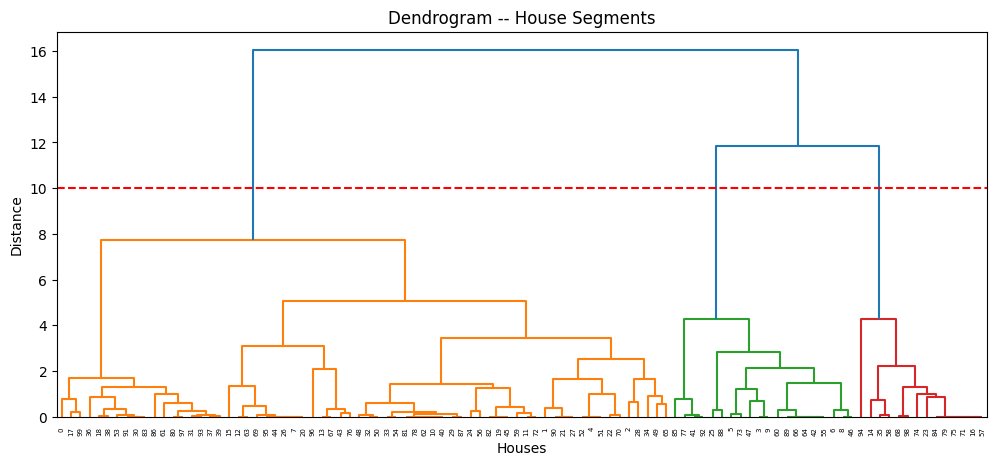

In [8]:
linked = linkage(X_scaled, method='ward')
plt.figure(figsize= (12, 5))
dendrogram(linked)
plt.title('Dendrogram -- House Segments')
plt.xlabel ('Houses'); plt.ylabel ('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

In [9]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['HC_Cluster'] = hc.fit_predict(X_scaled)

In [10]:
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(2))

HC_Cluster
0    66
2    20
1    14
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0           11235909.09      2.94   2.92       5.07
1           60335714.29      5.64   6.14       1.24
2           26460000.00      4.75   5.25      10.45


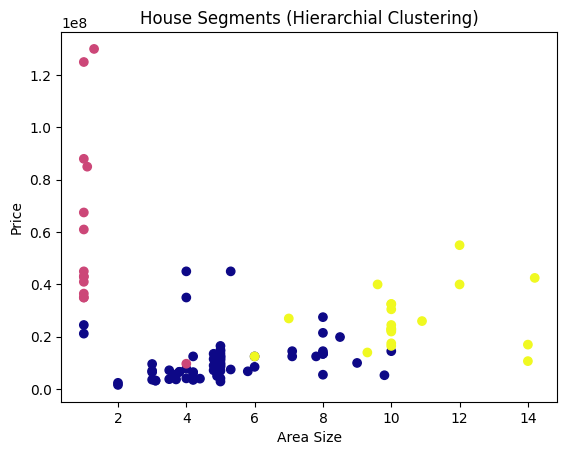

In [11]:
plt.scatter(df['Area Size'], df['price'], c=df['HC_Cluster'], cmap='plasma')
plt.xlabel('Area Size')
plt.ylabel('Price')
plt.title('House Segments (Hierarchial Clustering)')
plt.show()